# ClearBank — Análise Financeira com Python

Análise de transações bancárias com validação, métricas mensais, sinalização por valor e exportação JSON. Os dados são **fictícios**.

## Antes de executar

1. Coloque `transacoes.csv` na mesma pasta deste notebook. O CSV foi preparado separadamente e **não é criado nem sobrescrito pelo notebook**.
2. O arquivo precisa das colunas `id,data,cliente_id,tipo,valor,descricao,categoria`. Use UTF-8, vírgula como separador e ponto nos valores decimais.
3. A amostra fornecida tem **30 registros: 18 válidos em três meses e 12 descartados**, incluindo um ID duplicado. Há duas transações acima de R$ 10.000,00 e uma exatamente nesse limite.
4. Execute as células em ordem com Python 3.10+. No Colab, envie também `analise_pandas.py` para executar o opcional de pandas. Para execução local, instale `pandas matplotlib` com pip.
5. Salve o notebook após executar todas as células para preservar as saídas.

A análise principal usa apenas a biblioteca padrão. pandas e matplotlib ficam em células opcionais separadas. Datas e valores nas linhas inválidas não interrompem a análise; apenas os totais de descarte são exibidos.

**Regras adicionais:** espaços nas extremidades são removidos; tipos permanecem restritos a `credito` e `debito`; IDs inteiros repetidos são descartados após a primeira ocorrência válida. Valores não finitos são rejeitados. A conversão para `float` é validada, e as somas usam `Decimal` para evitar erros de ponto flutuante em dinheiro. A média é arredondada para centavos com `ROUND_HALF_UP`.

O sinalizador identifica somente valores acima do limite didático; não comprova fraude.

In [1]:
import csv
import json
import math
import re
from datetime import datetime
from decimal import Decimal, InvalidOperation, ROUND_HALF_UP
from pathlib import Path
from zoneinfo import ZoneInfo

LIMITE_SUSPEITO = 10000.00
COLUNAS = ['id', 'data', 'cliente_id', 'tipo', 'valor', 'descricao', 'categoria']
ARQUIVO_CSV = Path('transacoes.csv')
ARQUIVO_JSON = Path('relatorio.json')
FUSO = ZoneInfo('America/Recife')

print('Configuração carregada. Limite: R$ 10.000,00 (comparação estrita: >).')

Configuração carregada. Limite: R$ 10.000,00 (comparação estrita: >).


## 1. Leitura com csv.DictReader

Arquivo ausente retorna `None`, com uma mensagem explicativa. Cabeçalho incompatível ou falha de leitura também encerram apenas a análise, sem produzir um relatório novo. Arquivo só com cabeçalho é uma entrada vazia válida.

In [2]:
def ler_transacoes(caminho):
    """Lê linhas brutas; retorna None quando a leitura não pode ser concluída."""
    try:
        with open(caminho, 'r', encoding='utf-8-sig', newline='') as arquivo:
            leitor = csv.DictReader(arquivo)
            if leitor.fieldnames != COLUNAS:
                print('Cabeçalho inválido. Esperado: ' + ','.join(COLUNAS))
                return None
            return list(leitor)
    except FileNotFoundError:
        print(f'Arquivo não encontrado: {caminho}. Coloque o CSV na pasta do notebook.')
    except (OSError, UnicodeError, csv.Error) as erro:
        print(f'Não foi possível ler o CSV: {erro}')
    return None

linhas_teste = ler_transacoes(ARQUIVO_CSV)
assert linhas_teste is not None, 'Disponibilize transacoes.csv antes de continuar.'
print(f'Leitura concluída: {len(linhas_teste)} registros brutos.')

Leitura concluída: 30 registros brutos.


## 2. Validação e limpeza

`strptime` valida a existência da data; uma expressão regular exige também o formato exato `AAAA-MM-DD`. Os blocos `try/except` tratam separadamente ID, data e valor. Linhas rejeitadas não geram mensagens individuais.

In [3]:
def validar_data(texto):
    if not re.fullmatch(r'[0-9]{4}-[0-9]{2}-[0-9]{2}', texto):
        return None
    try:
        return datetime.strptime(texto, '%Y-%m-%d')
    except ValueError:
        return None


def validar_valor(texto):
    try:
        valor_float = float(texto)
    except (ValueError, OverflowError):
        return None
    if not math.isfinite(valor_float) or valor_float <= 0:
        return None
    try:
        return Decimal(texto)
    except InvalidOperation:
        return None


def validar_transacao(linha):
    if None in linha or any(linha.get(campo) is None for campo in COLUNAS):
        return None  # Linha com quantidade incorreta de campos.
    limpa = {campo: linha[campo].strip() for campo in COLUNAS}
    if not re.fullmatch(r'[+-]?[0-9]+', limpa['id']):
        return None
    try:
        identificador = int(limpa['id'])
    except ValueError:
        return None
    data = validar_data(limpa['data'])
    valor = validar_valor(limpa['valor'])
    if not limpa['cliente_id'] or limpa['tipo'] not in ('credito', 'debito'):
        return None
    if data is None or valor is None:
        return None
    return {**limpa, 'id': identificador, 'data': data, 'valor': valor}


def limpar_transacoes(linhas):
    validas, ids_vistos = [], set()
    invalidas = duplicadas = 0
    for linha in linhas:
        transacao = validar_transacao(linha)
        if transacao is None:
            invalidas += 1
        elif transacao['id'] in ids_vistos:
            invalidas += 1
            duplicadas += 1
        else:
            ids_vistos.add(transacao['id'])
            validas.append(transacao)
    limpeza = {'total_linhas_lidas': len(linhas),
               'total_transacoes_validas': len(validas),
               'total_transacoes_invalidas': invalidas,
               'duplicadas_descartadas': duplicadas}
    return validas, limpeza


transacoes_teste, limpeza_teste = limpar_transacoes(linhas_teste)
print(f"Total de linhas lidas: {limpeza_teste['total_linhas_lidas']}")
print(f"Linhas válidas: {limpeza_teste['total_transacoes_validas']}")
print(f"Linhas inválidas: {limpeza_teste['total_transacoes_invalidas']}")
print(f"Duplicadas entre as inválidas: {limpeza_teste['duplicadas_descartadas']}")

Total de linhas lidas: 30
Linhas válidas: 18
Linhas inválidas: 12
Duplicadas entre as inválidas: 1


## 3. Datas e métricas mensais

O período considera somente transações válidas. Os dias decorridos desde a mais antiga e a mais recente usam a data da execução em Recife. `amplitude_dias` é a distância entre essas duas transações. Com base vazia, essas informações ficam `null` no JSON.

A média usa todos os valores positivos do mês, sem subtrair débitos. Maior e menor transação incluem o registro completo; em empates, vale a primeira ocorrência no arquivo.

In [4]:
def dinheiro_json(valor):
    return float(valor.quantize(Decimal('0.01'), rounding=ROUND_HALF_UP))


def serializar_transacao(transacao):
    return {**transacao, 'data': transacao['data'].strftime('%Y-%m-%d'),
            'valor': dinheiro_json(transacao['valor'])}


def resumir_mes(transacoes):
    credito = sum((t['valor'] for t in transacoes if t['tipo'] == 'credito'), Decimal('0'))
    debito = sum((t['valor'] for t in transacoes if t['tipo'] == 'debito'), Decimal('0'))
    return {'quantidade': len(transacoes),
            'total_credito': dinheiro_json(credito),
            'total_debito': dinheiro_json(debito),
            'saldo': dinheiro_json(credito - debito),
            'media': dinheiro_json((credito + debito) / len(transacoes)),
            'maior_transacao': serializar_transacao(max(transacoes, key=lambda t: t['valor'])),
            'menor_transacao': serializar_transacao(min(transacoes, key=lambda t: t['valor']))}


def calcular_periodo(transacoes, referencia):
    if not transacoes:
        return None
    inicio = min(t['data'].date() for t in transacoes)
    fim = max(t['data'].date() for t in transacoes)
    return {'inicio': inicio.isoformat(), 'fim': fim.isoformat(),
            'dias_desde_mais_antiga': (referencia - inicio).days,
            'dias_desde_mais_recente': (referencia - fim).days,
            'amplitude_dias': (fim - inicio).days}


def gerar_relatorio(transacoes, limpeza, referencia=None):
    referencia = referencia or datetime.now(FUSO).date()
    grupos = {}
    for transacao in transacoes:
        mes = transacao['data'].strftime('%Y-%m')
        grupos.setdefault(mes, []).append(transacao)
    suspeitas = [serializar_transacao(t) for t in transacoes
                 if t['valor'] > Decimal(str(LIMITE_SUSPEITO))]
    return {'gerado_em': referencia.isoformat(), **limpeza,
            'periodo_analisado': calcular_periodo(transacoes, referencia),
            'limite_suspeito': LIMITE_SUSPEITO,
            'resumo_mensal': {mes: resumir_mes(grupos[mes]) for mes in sorted(grupos)},
            'transacoes_suspeitas': suspeitas}


relatorio_teste = gerar_relatorio(transacoes_teste, limpeza_teste)
print('Meses encontrados:', ', '.join(relatorio_teste['resumo_mensal']))
print('Período:', relatorio_teste['periodo_analisado']['inicio'], '→',
      relatorio_teste['periodo_analisado']['fim'])
print('Transações acima do limite:', len(relatorio_teste['transacoes_suspeitas']))

Meses encontrados: 2026-01, 2026-02, 2026-03
Período: 2026-01-05 → 2026-03-30
Transações acima do limite: 2


## 4. Exportação JSON e relatório formatado

In [5]:
def salvar_json(relatorio, caminho=ARQUIVO_JSON):
    try:
        with open(caminho, 'w', encoding='utf-8') as arquivo:
            json.dump(relatorio, arquivo, ensure_ascii=False, indent=2, allow_nan=False)
            arquivo.write('\n')
    except (OSError, ValueError, TypeError) as erro:
        print(f'Não foi possível salvar o JSON: {erro}')
        return False
    return True


def formatar_brl(valor):
    return f'R$ {valor:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


def exibir_relatorio(relatorio):
    print('===== LIMPEZA E PERÍODO =====')
    print(f"Total de linhas lidas: {relatorio['total_linhas_lidas']}")
    print(f"Linhas válidas: {relatorio['total_transacoes_validas']}")
    print(f"Linhas inválidas: {relatorio['total_transacoes_invalidas']}")
    print(f"Duplicadas entre as inválidas: {relatorio['duplicadas_descartadas']}")
    periodo = relatorio['periodo_analisado']
    if periodo:
        print(f"Período analisado: {periodo['inicio']} → {periodo['fim']}")
        print(f"Dias desde a mais antiga: {periodo['dias_desde_mais_antiga']}")
        print(f"Dias desde a mais recente: {periodo['dias_desde_mais_recente']}")
        print(f"Amplitude do período: {periodo['amplitude_dias']} dias")
    else:
        print('Período analisado: sem transações válidas.')
    print('\n===== RELATÓRIO MENSAL =====')
    for mes, dados in relatorio['resumo_mensal'].items():
        print(f"\nMês: {mes}\n  Transações: {dados['quantidade']}")
        for rotulo, chave in [('Total crédito', 'total_credito'), ('Total débito', 'total_debito'),
                             ('Saldo', 'saldo'), ('Média', 'media')]:
            print(f"  {rotulo + ':':15} {formatar_brl(dados[chave])}")
        for rotulo, chave in [('Maior valor', 'maior_transacao'), ('Menor valor', 'menor_transacao')]:
            transacao = dados[chave]
            print(f"  {rotulo + ':':15} {formatar_brl(transacao['valor'])} (ID {transacao['id']})")
    if not relatorio['resumo_mensal']:
        print('Sem movimentações válidas para agrupar.')
    print('\n===== TRANSAÇÕES SUSPEITAS =====')
    for transacao in relatorio['transacoes_suspeitas']:
        print(f"ID: {transacao['id']} | Cliente: {transacao['cliente_id']} | "
              f"Data: {transacao['data']} | Valor: {formatar_brl(transacao['valor'])}")
    if not relatorio['transacoes_suspeitas']:
        print('Nenhuma transação suspeita encontrada.')


assert formatar_brl(1234.5) == 'R$ 1.234,50'
print('Exportação e exibição prontas. Formatação monetária validada.')

Exportação e exibição prontas. Formatação monetária validada.


## 5. Testes de regras e situações de erro

Os testes usam dados em memória e arquivos temporários, sem alterar o CSV. As contagens esperadas são específicas da amostra fornecida. Se você substituir o CSV por outra base, ajuste esses resultados de referência.

In [6]:
from contextlib import redirect_stdout
from io import StringIO
from tempfile import TemporaryDirectory

base = dict(zip(COLUNAS, ['90', '2026-01-01', 'CLI090', 'credito', '100.00', 'Teste', 'teste']))
casos_invalidos = [
    {'id': ''}, {'id': 'abc'}, {'id': '1.5'}, {'cliente_id': '   '},
    {'data': '2026-2-01'}, {'data': '2026-02-30'}, {'data': '01/02/2026'},
    {'tipo': 'pix'}, {'valor': 'abc'}, {'valor': '0'}, {'valor': '-1'},
    {'valor': 'NaN'}, {'valor': 'Infinity'}, {'valor': ''},
]
for alteracao in casos_invalidos:
    assert validar_transacao({**base, **alteracao}) is None, alteracao
assert validar_transacao(base) is not None
assert validar_transacao({**base, 'data': '2024-02-29'}) is not None
assert validar_transacao({**base, 'data': '2026-02-29'}) is None
assert validar_transacao({**base, None: ['campo extra']}) is None
assert validar_transacao({**base, 'valor': None}) is None
validas, limpeza = limpar_transacoes([{**base, 'valor': 'abc'}, base, base])
assert len(validas) == 1 and limpeza['total_transacoes_invalidas'] == 2
assert limpeza['duplicadas_descartadas'] == 1
limites = [validar_transacao({**base, 'id': str(i), 'valor': valor})
           for i, valor in enumerate(['9999.99', '10000.00', '10000.01'], start=100)]
assert [t['id'] for t in gerar_relatorio(limites, {})['transacoes_suspeitas']] == [102]
assert limpeza_teste == {'total_linhas_lidas': 30, 'total_transacoes_validas': 18,
                        'total_transacoes_invalidas': 12, 'duplicadas_descartadas': 1}
for mes, esperado in {'2026-01': (15700.00, 1030.40, 14669.60, 2788.40),
                      '2026-02': (19300.00, 1660.65, 17639.35, 3493.44),
                      '2026-03': (5300.00, 13220.25, -7920.25, 3086.71)}.items():
    resumo = relatorio_teste['resumo_mensal'][mes]
    assert resumo['quantidade'] == 6
    assert tuple(resumo[c] for c in ('total_credito', 'total_debito', 'saldo', 'media')) == esperado
assert relatorio_teste['periodo_analisado']['amplitude_dias'] == 84
assert [t['id'] for t in relatorio_teste['transacoes_suspeitas']] == [7, 13]
with TemporaryDirectory() as pasta:
    with redirect_stdout(StringIO()) as captura:
        assert ler_transacoes(Path(pasta) / 'ausente.csv') is None
    print('Teste de arquivo ausente:', captura.getvalue().strip())
    vazio = Path(pasta) / 'vazio.csv'
    vazio.write_text(','.join(COLUNAS) + '\n', encoding='utf-8')
    assert ler_transacoes(vazio) == []
    bruto_vazio, limpeza_vazia = limpar_transacoes([])
    relatorio_vazio = gerar_relatorio(bruto_vazio, limpeza_vazia)
    assert relatorio_vazio['periodo_analisado'] is None
    with redirect_stdout(StringIO()) as captura:
        exibir_relatorio(relatorio_vazio)
    assert 'Nenhuma transação suspeita encontrada.' in captura.getvalue()
    destino = Path(pasta) / 'teste.json'
    assert salvar_json(relatorio_teste, destino)
    assert json.loads(destino.read_text(encoding='utf-8')) == relatorio_teste
    with redirect_stdout(StringIO()) as captura:
        assert salvar_json(relatorio_teste, Path(pasta) / 'inexistente' / 'teste.json') is False
print('Testes aprovados: validação, duplicatas, limite, métricas, datas, base vazia e JSON.')

Teste de arquivo ausente: Arquivo não encontrado: /tmp/tmp6ll4hjtb/ausente.csv. Coloque o CSV na pasta do notebook.
Testes aprovados: validação, duplicatas, limite, métricas, datas, base vazia e JSON.


## 6. Execução principal — solução nativa completa

In [7]:
def executar_analise(caminho_csv=ARQUIVO_CSV, caminho_json=ARQUIVO_JSON):
    linhas = ler_transacoes(caminho_csv)
    if linhas is None:
        return None
    transacoes, limpeza = limpar_transacoes(linhas)
    relatorio = gerar_relatorio(transacoes, limpeza)
    exibir_relatorio(relatorio)
    if salvar_json(relatorio, caminho_json):
        print(f'\nRelatório salvo em: {caminho_json}')
    return relatorio


relatorio = executar_analise()
assert relatorio is not None, 'Corrija o arquivo de entrada e execute novamente.'

===== LIMPEZA E PERÍODO =====
Total de linhas lidas: 30
Linhas válidas: 18
Linhas inválidas: 12
Duplicadas entre as inválidas: 1
Período analisado: 2026-01-05 → 2026-03-30
Dias desde a mais antiga: 309
Dias desde a mais recente: 225
Amplitude do período: 84 dias

===== RELATÓRIO MENSAL =====

Mês: 2026-01
  Transações: 6
  Total crédito:  R$ 15.700,00
  Total débito:   R$ 1.030,40
  Saldo:          R$ 14.669,60
  Média:          R$ 2.788,40
  Maior valor:    R$ 10.000,00 (ID 6)
  Menor valor:    R$ 99,90 (ID 5)

Mês: 2026-02
  Transações: 6
  Total crédito:  R$ 19.300,00
  Total débito:   R$ 1.660,65
  Saldo:          R$ 17.639,35
  Média:          R$ 3.493,44
  Maior valor:    R$ 15.000,00 (ID 7)
  Menor valor:    R$ 89,90 (ID 12)

Mês: 2026-03
  Transações: 6
  Total crédito:  R$ 5.300,00
  Total débito:   R$ 13.220,25
  Saldo:          R$ -7.920,25
  Média:          R$ 3.086,71
  Maior valor:    R$ 12.500,00 (ID 13)
  Menor valor:    R$ 59,90 (ID 18)

===== TRANSAÇÕES SUSPEITAS ====

## 7. Comparação independente com pandas (opcional)

O arquivo separado `analise_pandas.py` usa `pd.read_csv`, filtra os registros, elimina IDs duplicados e calcula métricas com `groupby`. Ele não importa a solução nativa. A comparação abaixo confere todas as métricas de cada mês, os registros extremos, as contagens e as suspeitas.

In [8]:
import importlib.util

if importlib.util.find_spec('pandas') is None:
    print('Opcional não executado: instale pandas com pip install pandas.')
elif not Path('analise_pandas.py').is_file():
    print('Opcional não executado: envie analise_pandas.py para a pasta do notebook.')
else:
    import runpy
    modulo_pandas = runpy.run_path('analise_pandas.py', run_name='comparacao_notebook')
    resultado_pandas = modulo_pandas['analisar_pandas'](ARQUIVO_CSV)
    for chave in ('total_linhas_lidas', 'total_transacoes_validas',
                  'total_transacoes_invalidas', 'duplicadas_descartadas',
                  'resumo_mensal', 'transacoes_suspeitas'):
        assert resultado_pandas[chave] == relatorio[chave], f'Divergência em {chave}'
    print('pandas × solução nativa: todos os resultados comparados são iguais.')
    for mes, resumo in resultado_pandas['resumo_mensal'].items():
        print(f"{mes}: {resumo['quantidade']} transações | saldo {formatar_brl(resumo['saldo'])}")

pandas × solução nativa: todos os resultados comparados são iguais.
2026-01: 6 transações | saldo R$ 14.669,60
2026-02: 6 transações | saldo R$ 17.639,35
2026-03: 6 transações | saldo R$ -7.920,25


## 8. Gráfico do saldo mensal (opcional)

Barras abaixo de zero representam meses em que os débitos superaram os créditos. A imagem é salva em `grafico.png`.

Gráfico salvo em: grafico.png


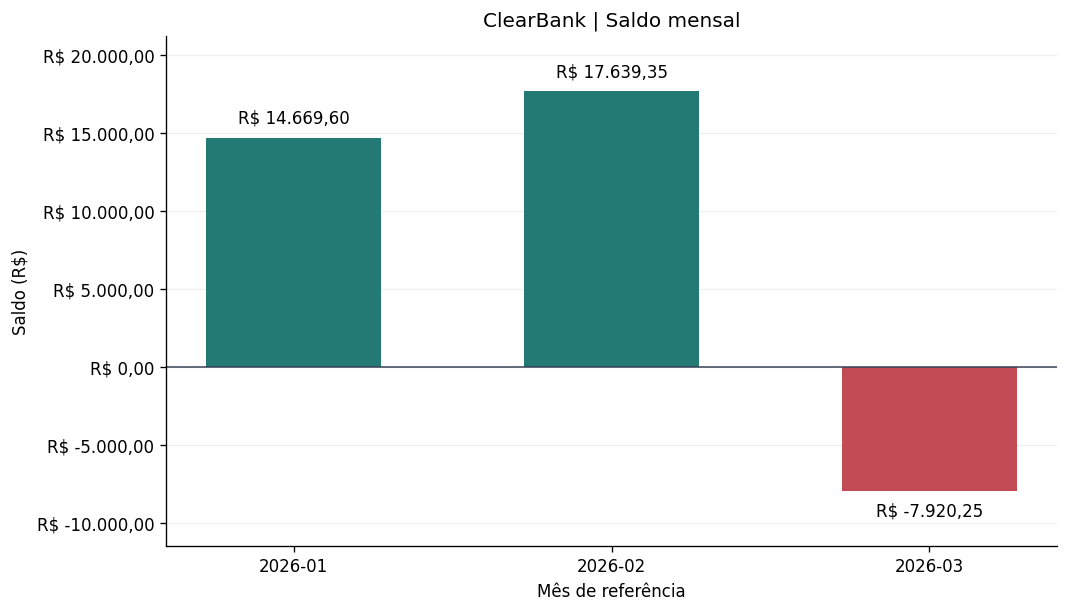

In [9]:
if importlib.util.find_spec('matplotlib') is None:
    print('Opcional não executado: instale matplotlib com pip install matplotlib.')
elif not relatorio['resumo_mensal']:
    print('Sem dados válidos para gerar o gráfico.')
else:
    import matplotlib.pyplot as plt
    from matplotlib.ticker import FuncFormatter

    meses = list(relatorio['resumo_mensal'])
    saldos = [relatorio['resumo_mensal'][mes]['saldo'] for mes in meses]
    cores = ['#237a75' if saldo >= 0 else '#c24c55' for saldo in saldos]
    fig, ax = plt.subplots(figsize=(9, 5.2))
    barras = ax.bar(meses, saldos, color=cores, width=0.55)
    ax.axhline(0, color='#344054', linewidth=0.9)
    ax.set(title='ClearBank | Saldo mensal', xlabel='Mês de referência', ylabel='Saldo (R$)')
    ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, pos: formatar_brl(valor)))
    ax.grid(axis='y', alpha=0.18)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    margem = max(abs(saldo) for saldo in saldos) * 0.04
    for barra, saldo in zip(barras, saldos):
        ax.text(barra.get_x() + barra.get_width() / 2, saldo + (margem if saldo >= 0 else -margem),
                formatar_brl(saldo), ha='center', va='bottom' if saldo >= 0 else 'top', fontsize=10)
    ax.set_ylim(min(0, min(saldos)) - margem * 5, max(0, max(saldos)) + margem * 5)
    fig.tight_layout()
    fig.savefig('grafico.png', dpi=160, facecolor='white')
    plt.show()
    print('Gráfico salvo em: grafico.png')